<a href="https://colab.research.google.com/github/pj0622/Python_CSIT_104/blob/main/2026_11_16_PHYS230_nonlinear_fit_capacitor_discharge_and_charge_example_(class).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Text(0.5, 1.0, 'Example: discharging capacitor through a resistor')

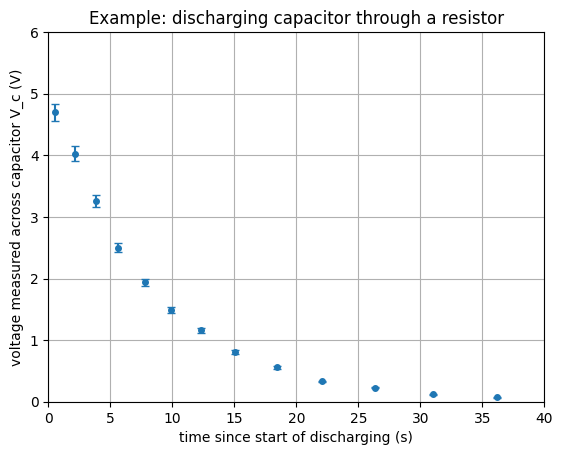

In [ ]:
#Download the fitting code from GitHub into this Colab session. Rerun this cell every new session, since Colab deletes the file when the session ends.
!wget -q -O phys230fit.py https://raw.githubusercontent.com/KentLeung/montclair-physics-labs/main/phys230fit.py

import numpy as np
import matplotlib.pyplot as plt
from phys230fit import nonlinear_weighted_fit

#Example data (simulated) of voltage across capacitor Vc versus time while discharging through a resistor.
#The uncertainty is different for each point. Early on the voltage drops quickly, so the uncertainty in exactly when each reading was taken (about 0.25 s)
#gives a large uncertainty in the voltage. Later the voltage changes slowly, and the uncertainty is set by reading the multimeter.
time_dis = np.array([0.52,  2.14,  3.87,  5.61,  7.80,  9.93,  12.31, 15.08, 18.42, 22.05, 26.33, 31.02, 36.20]) #time since start of discharging (s)
Vc_dis = np.array([  4.701, 4.027, 3.259, 2.503, 1.936, 1.485, 1.157, 0.811, 0.558, 0.332, 0.225, 0.118, 0.071]) #voltage across capacitor reading (V)
Vc_dis_err=np.array([0.14,  0.12,  0.10,  0.08,  0.06,  0.05,  0.04,  0.03,  0.02,  0.01,  0.01,  0.01,  0.01]) #uncertainty in each voltage reading (V)

plt.figure(); plt.grid()
plt.errorbar(time_dis, Vc_dis, Vc_dis_err, fmt = 'o', markersize=4, capsize=3)
plt.xlim([0,40])
plt.ylim([0,6])
plt.xlabel('time since start of discharging (s)')
plt.ylabel('voltage measured across capacitor V_c (V)')
plt.title('Example: discharging capacitor through a resistor')


 Best fit parameters from nonlinear_weighted_fit:
Parameter 1:  5.061771 ± 0.08122338
Parameter 2:  8.248924 ± 0.08217421
chi-squared = 10.742,  degrees of freedom = 11,  reduced chi-squared = 0.9765455


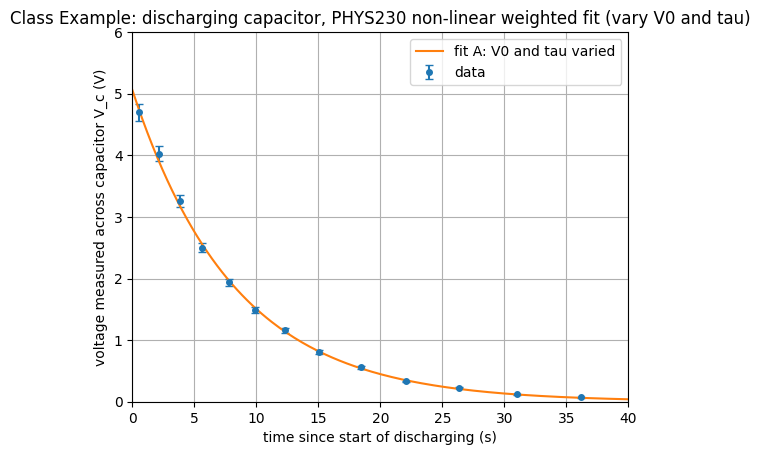

In [ ]:
def exp_decay_func(t, V0, tau): # Model for the fit. First input must be 'x', followed by the free parameters.
  return V0*np.exp(-t/tau) # V0 = voltage at t = 0 s (V), tau = RC time constant (s). Returns the 'y' value.

initial_guess_A = [5, 10] # initial guess for the free parameters [V0 in V, tau in s]. The order is the same as in the input for exp_decay_func

params_A, params_A_err = nonlinear_weighted_fit(time_dis, Vc_dis, Vc_dis_err, exp_decay_func, initial_guess_A) # params_A = [V0, tau], params_A_err = their uncertainties

V0_fit_A = params_A[0] # best-fit V0 (V)
tau_fit_A = params_A[1] # best-fit tau (s)

t_plot = np.linspace(0,40,200) #finely spaced times between 0 s and 40 s for plotting a smooth fit line

plt.figure(); plt.grid()
plt.errorbar(time_dis, Vc_dis, Vc_dis_err, fmt = 'o', markersize=4, capsize=3, label='data')
plt.plot(t_plot, exp_decay_func(t_plot, V0_fit_A, tau_fit_A), label='fit A: V0 and tau varied')
plt.xlim([0,40])
plt.ylim([0,6])
plt.xlabel('time since start of discharging (s)')
plt.ylabel('voltage measured across capacitor V_c (V)')
plt.title('Class Example: discharging capacitor, PHYS230 non-linear weighted fit (vary V0 and tau)')
plt.legend()


 ---- Fitting V0 fixed and tau varied -----

 Best fit parameters from nonlinear_weighted_fit:
Parameter 1:  5  (fixed)
Parameter 2:  8.298927 ± 0.05081098
chi-squared = 11.31911,  degrees of freedom = 12,  reduced chi-squared = 0.9432594


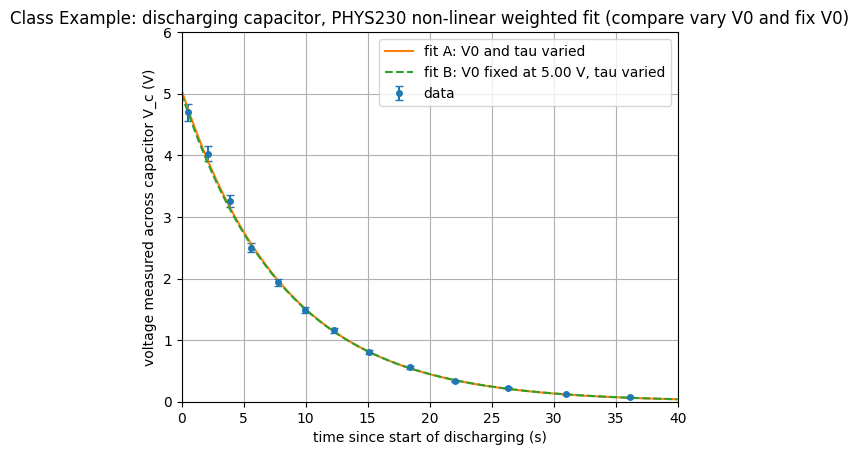

In [ ]:
#Suppose the voltage across the capacitor just before discharging was measured separately as 5.00 V. Hold V0 fixed at 5.00 V and fit only tau.
print('\n ---- Fitting V0 fixed and tau varied -----')
initial_guess_B = [5.00, 10] # [V0 in V (held fixed at this value), tau in s (initial guess)]

params_B, params_B_err = nonlinear_weighted_fit(time_dis, Vc_dis, Vc_dis_err, exp_decay_func, initial_guess_B, vary=[False, True]) # vary: False = held fixed, True = fitted

V0_fit_B = params_B[0] # V0, held fixed at 5.00 V (V)
tau_fit_B = params_B[1] # best-fit tau (s)

plt.figure(); plt.grid()
plt.errorbar(time_dis, Vc_dis, Vc_dis_err, fmt = 'o', markersize=4, capsize=3, label='data')
plt.plot(t_plot, exp_decay_func(t_plot, V0_fit_A, tau_fit_A), label='fit A: V0 and tau varied')
plt.plot(t_plot, exp_decay_func(t_plot, V0_fit_B, tau_fit_B), '--', label='fit B: V0 fixed at 5.00 V, tau varied')
plt.xlim([0,40])
plt.ylim([0,6])
plt.xlabel('time since start of discharging (s)')
plt.ylabel('voltage measured across capacitor V_c (V)')
plt.title('Class Example: discharging capacitor, PHYS230 non-linear weighted fit (compare vary V0 and fix V0)')
plt.legend()

In [ ]:
#--- EXERCISE FOR YOU TO PRACTICE. FIT YOUR CAPACITOR CHARGING CODE BELOW ------

#Your capacitor charging data. Replace the empty arrays with your measurements, separated by commas. All three arrays must be the same length.
time_chg = np.array([ ]) #time since start of charging (s)
Vc_chg = np.array([ ]) #voltage across capacitor reading (V)
Vc_chg_err = np.array([ ]) #uncertainty in each voltage reading (V)

def exp_buildup_func(t, V_inf, tau): # Model for charging. V_inf = V_infinity, the final voltage as t goes to infinity (V), tau = RC time constant (s).
  return  # complete this line: the voltage across the capacitor at time t while charging

#Complete the code below to fit your charging data with exp_buildup_func, with both V_inf and tau varied, and plot the data with the fit.
#Use Fit A above as a guide:
#  give an initial guess for V_inf and tau
#  call nonlinear_weighted_fit
#  plot your data with error bars and the fit curve, with axis labels (with units), a title and a legend

initial_guess_chg = [ ] # initial guess for the free parameters [V_inf in V, tau in s]

params_chg, params_chg_err = nonlinear_weighted_fit( )

plt.figure(); plt.grid()

TypeError: nonlinear_weighted_fit() missing 5 required positional arguments: 'x_data', 'y_data', 'y_error', 'fit_func', and 'initial_guess'